In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import sklearn

import pickle

In [4]:
df = pd.read_csv('student_performance_data.csv')

# DOMAIN ANALYSIS

# BASIC CHECKS

In [5]:
df.head()

,Student_ID,Study_Hours,Attendance_Pct,Previous_Score,Sleep_Hours,Final_Score
0,STU_001,4.0,85.7,45.7,5.7,58.4
1,STU_002,8.6,63.4,89.6,6.1,89.5
2,STU_003,6.9,66.5,67.8,5.7,79.6
3,STU_004,5.8,95.9,85.5,5.4,89.9
4,STU_005,2.2,84.3,57.6,5.5,63.7


In [6]:
df.tail()

,Student_ID,Study_Hours,Attendance_Pct,Previous_Score,Sleep_Hours,Final_Score
195,STU_196,3.8,97.2,66.1,8.5,68.7
196,STU_197,6.8,94.3,76.7,8.7,88.0
197,STU_198,8.2,77.2,49.5,7.3,77.9
198,STU_199,8.1,90.0,50.6,7.8,79.7
199,STU_200,7.2,90.2,42.2,8.7,76.8


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Student_ID      200 non-null    str    
 1   Study_Hours     200 non-null    float64
 2   Attendance_Pct  200 non-null    float64
 3   Previous_Score  200 non-null    float64
 4   Sleep_Hours     200 non-null    float64
 5   Final_Score     200 non-null    float64
dtypes: float64(5), str(1)
memory usage: 10.9 KB


In [8]:
df.describe()

,Study_Hours,Attendance_Pct,Previous_Score,Sleep_Hours,Final_Score
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,4.874500,80.171000,68.637500,6.914000,71.975500
std,2.361011,11.718497,16.898477,1.120797,11.132882
min,1.000000,60.200000,40.600000,5.100000,45.000000
25%,2.800000,70.450000,54.050000,5.900000,63.700000
50%,5.000000,81.650000,68.900000,6.900000,72.400000
75%,7.025000,89.675000,84.625000,7.900000,79.050000
max,8.900000,99.600000,95.000000,9.000000,100.000000


In [10]:
df.columns

Index(['Student_ID', 'Study_Hours', 'Attendance_Pct', 'Previous_Score',
       'Sleep_Hours', 'Final_Score'],
      dtype='str')

In [12]:
df.shape

(200, 6)

# EDA

<Axes: xlabel='Final_Score', ylabel='Count'>

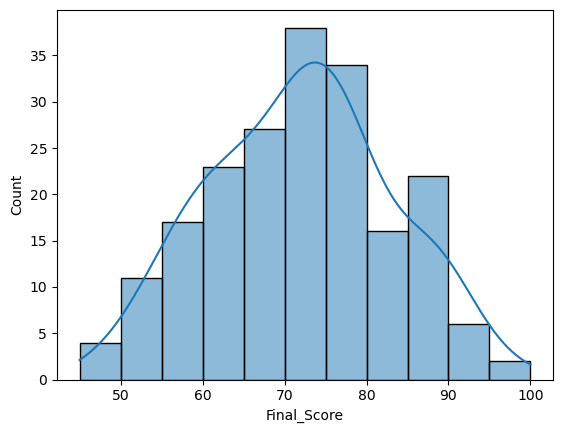

In [14]:
sns.histplot(df.Final_Score,kde=True)

<Axes: >

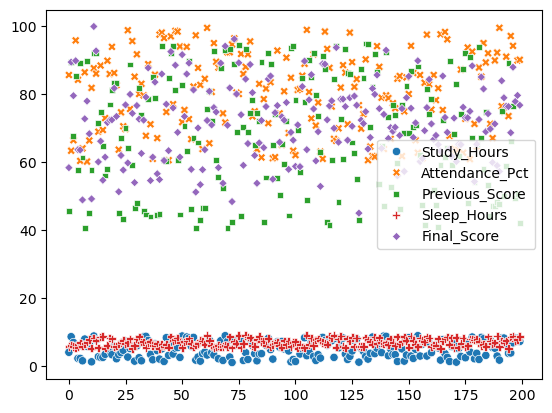

In [17]:
sns.scatterplot(df)

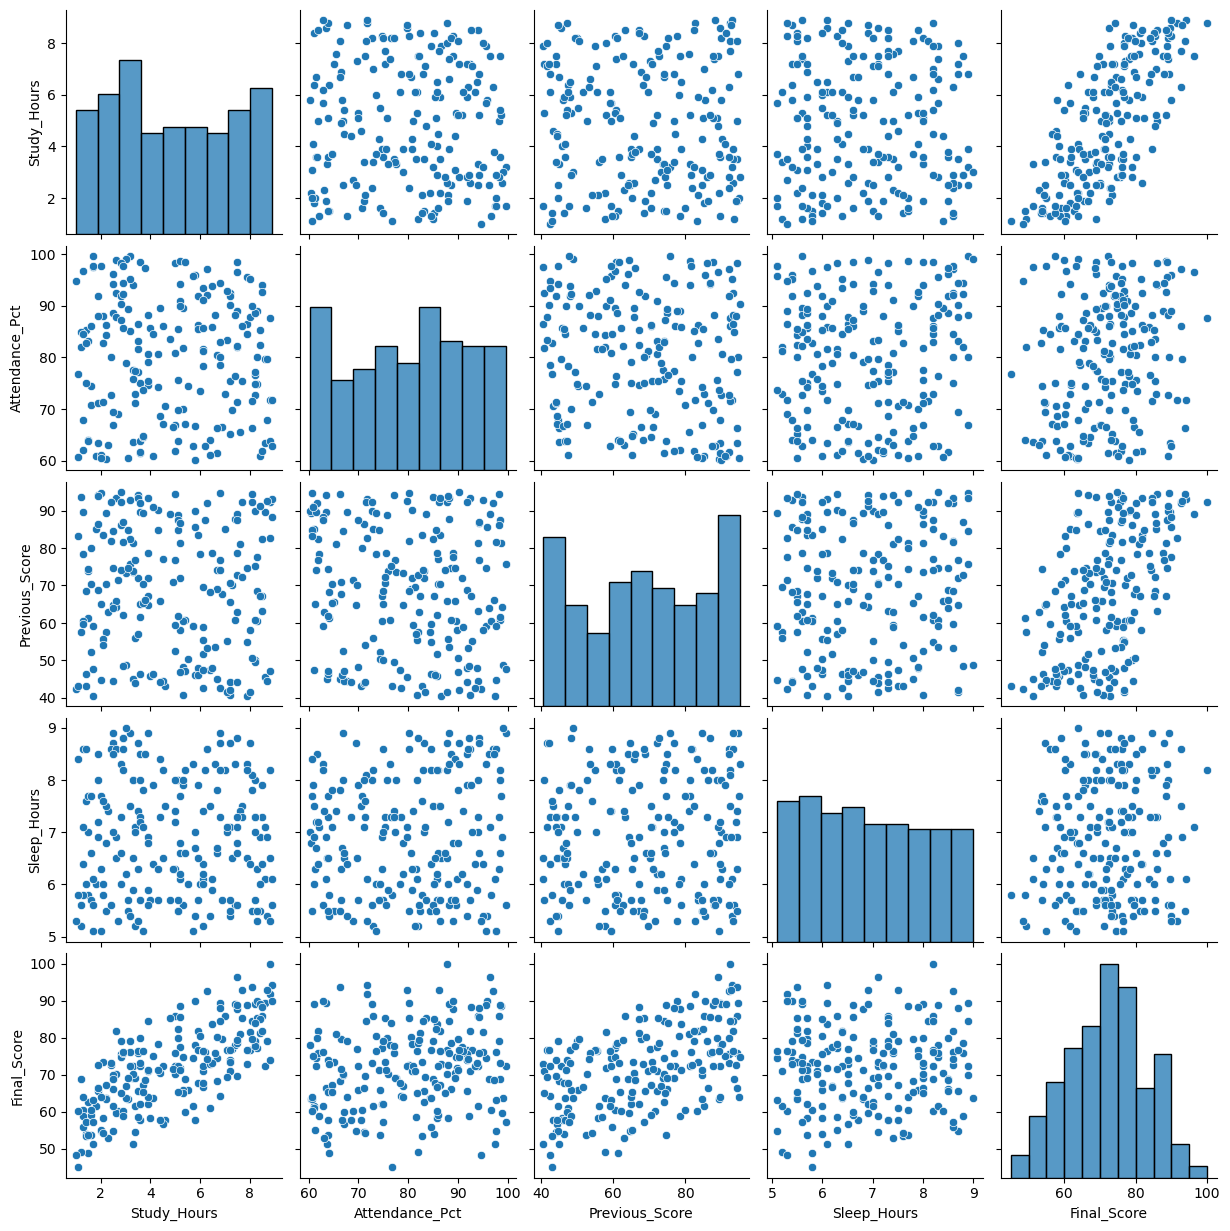

In [18]:
sns.pairplot(df)

<Axes: ylabel='Sleep_Hours'>

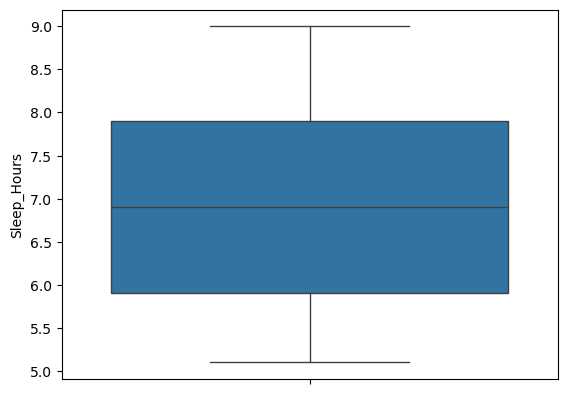

In [28]:
sns.boxplot(df.Sleep_Hours)

In [22]:
df.columns

Index(['Student_ID', 'Study_Hours', 'Attendance_Pct', 'Previous_Score',
       'Sleep_Hours', 'Final_Score'],
      dtype='str')

In [32]:
df = df.drop('Student_ID',axis = 1)

<Axes: >

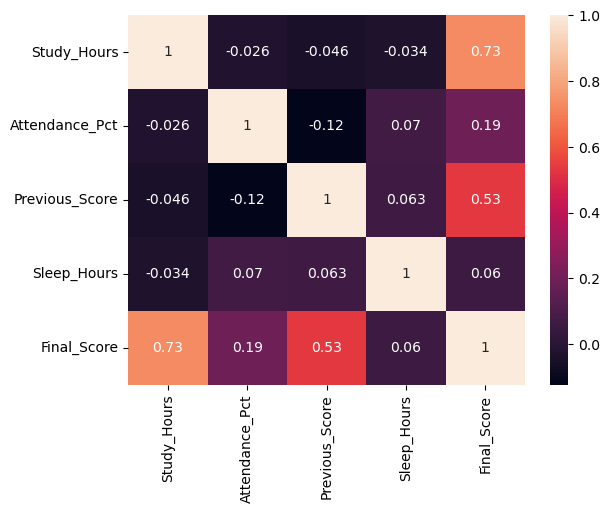

In [33]:
sns.heatmap(df.corr(),annot =True)

# Model Selection

In [35]:
from sklearn.linear_model import LinearRegression

In [37]:
model = LinearRegression()

In [36]:
from sklearn.model_selection import train_test_split

In [40]:
X = df.drop('Final_Score',axis=1)
y = df.Final_Score

In [42]:
X

,Study_Hours,Attendance_Pct,Previous_Score,Sleep_Hours
0,4.0,85.7,45.7,5.7
1,8.6,63.4,89.6,6.1
2,6.9,66.5,67.8,5.7
3,5.8,95.9,85.5,5.4
4,2.2,84.3,57.6,5.5
...,...,...,...,...
195,3.8,97.2,66.1,8.5
196,6.8,94.3,76.7,8.7
197,8.2,77.2,49.5,7.3
198,8.1,90.0,50.6,7.8


In [43]:
y

0      58.4
1      89.5
2      79.6
3      89.9
4      63.7
       ... 
195    68.7
196    88.0
197    77.9
198    79.7
199    76.8
Name: Final_Score, Length: 200, dtype: float64

In [44]:
x_train,x_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=33)

In [45]:
x_test

,Study_Hours,Attendance_Pct,Previous_Score,Sleep_Hours
15,2.5,69.5,64.7,8.7
171,1.1,60.7,83.1,8.4
103,5.1,85.5,84.8,5.5
119,5.3,70.0,48.3,7.9
116,7.4,76.4,60.7,8.3
162,6.1,78.3,47.5,6.0
54,5.8,66.8,46.1,6.7
17,5.2,89.9,58.1,6.1
117,2.5,66.9,84.6,8.9
100,1.3,62.1,78.4,7.1


In [46]:
x_train

,Study_Hours,Attendance_Pct,Previous_Score,Sleep_Hours
82,3.6,75.0,65.0,5.7
101,6.1,81.3,69.5,5.2
47,5.2,98.7,81.4,7.7
27,5.1,75.7,88.8,8.0
44,3.1,60.6,84.7,5.5
...,...,...,...,...
57,2.6,87.8,65.8,6.5
146,5.9,85.4,46.2,6.5
66,2.1,87.9,55.7,6.0
135,3.6,61.6,92.0,8.5


In [47]:
y_test

15     54.7
171    60.2
103    82.3
119    65.9
116    78.1
162    67.9
54     57.9
17     71.7
117    70.0
100    58.8
109    60.4
8      78.0
118    93.8
38     83.6
29     54.0
149    79.0
81     80.5
126    79.5
189    59.0
85     72.3
197    77.9
152    67.3
50     91.7
62     80.9
92     76.7
34     79.2
153    71.6
14     66.2
91     74.6
173    65.2
199    76.8
177    75.0
141    67.0
125    70.6
89     85.4
75     89.3
71     81.9
195    68.7
182    85.1
112    89.0
Name: Final_Score, dtype: float64

In [48]:
y_train

82     62.0
101    71.0
47     88.6
27     80.0
44     63.4
       ... 
57     70.1
146    67.9
66     58.4
135    80.0
20     81.8
Name: Final_Score, Length: 160, dtype: float64

In [55]:
model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [56]:
model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [58]:
y_pred = model.predict(x_test)

In [52]:
print(len(x_train))
print(len(x_test))
print(len(y_train))
print(len(y_test))

160
40
160
40


# Model Evaluation

In [53]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

In [59]:
mean_absolute_error(y_test,y_pred)

2.445988040601904

In [60]:
mean_squared_error(y_test,y_pred)

8.987686679940012

In [61]:
root_mean_squared_error(y_test,y_pred)

2.9979470775749215

In [62]:
r2_score(y_test,y_pred)

0.9131969957615057

In [64]:
y_pred_train = model.predict(x_train)

In [65]:
r2_score(y_pred_train,y_train)

0.929353922972501

# means model is generalized

## predicting unseen data

In [69]:
new_student = pd.DataFrame({
    'Study_Hours':[8], 'Attendance_Pct':[96],'Previous_Score':[89],'Sleep_Hours':[7]
})

In [70]:
model.predict(new_student)

array([95.12362089])

# Saving model

In [72]:
pickle.dump(model,open('preprocessed.pkl','wb'))